# 00 · A complete mini LLM in one notebook

Everything needed to build a GPT-style language model, **in one place and with no project imports** — only PyTorch:

1. **Data** — a text corpus (built-in generator, or any `.txt` you provide)
2. **Tokenizer** — byte-level BPE, trained on the corpus
3. **Model** — a modern decoder-only transformer: token embeddings, **RoPE**, **RMSNorm**, causal multi-head attention, **SwiGLU** feed-forward, tied output head (the Llama recipe, miniaturized)
4. **Training** — AdamW with weight-decay groups, warmup + cosine LR, gradient clipping, train/val curves
5. **Evaluation** — perplexity, and the theoretical loss floor of the data
6. **Generation** — temperature, top-k and top-p sampling
7. **Save / load** — a self-contained checkpoint

The other notebooks take each piece apart in depth (01 tokenization → 02 attention → 04 FFN → 05 pre-training → 06 inference); this one shows how they **fit together**. The same code is exported to `scripts/mini_llm.py`: `python scripts/mini_llm.py` trains the model from the command line.

**Runtime:** about a minute on a laptop GPU (RTX 3060), 3–5 minutes on a CPU. The code picks the GPU automatically when PyTorch sees one.

## 0. Configuration
All the knobs in one place. Doubling `d_model`/`n_layers` or `steps` gives better text at the cost of time.

In [1]:
import math, os, re, time, random, json
from collections import Counter
import torch
import torch.nn as nn
import torch.nn.functional as F

CFG = dict(
    text_path=None,          # e.g. "input.txt" (tiny Shakespeare); None uses the built-in synthetic corpus
    vocab_size=512,          # 256 raw bytes plus the learned merges
    block_size=128,          # context length in tokens
    d_model=192, n_layers=4, n_heads=6,
    dropout=0.0,
    batch_size=32, steps=800, max_lr=3e-3, min_lr=3e-4, warmup=80, weight_decay=0.1, grad_clip=1.0,
    eval_every=100, eval_batches=20, seed=0,
)
torch.manual_seed(CFG["seed"]); random.seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
# On an NVIDIA GPU we train in bfloat16 mixed precision (Ampere or newer) and let matmuls use TF32: same results, much faster.
use_bf16 = device == "cuda" and torch.cuda.is_bf16_supported()
torch.set_float32_matmul_precision("high")
print("torch", torch.__version__, "| device", device, f"({torch.cuda.get_device_name(0)})" if device == "cuda" else "", "| bf16 autocast:", use_bf16)

torch 2.14.1+cu130 | device cuda (NVIDIA GeForce RTX 3060 Laptop GPU) | bf16 autocast: True


## 1. Data

To stay offline we generate English-like text from a small grammar: each sentence picks a subject, verb, object and place at random. Because we know exactly how it is generated, we can compute the **best loss any model could reach** (section 5) — a luxury you never have with real text. Point `text_path` to any `.txt` file to train on real data instead, e.g. tiny Shakespeare:
`curl -O https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt`.

In [2]:
SUBJECTS = ["the old sailor", "a young fox", "the tired queen", "my neighbour", "the little robot", "a clever student",
            "the quiet painter", "our teacher"]
VERBS = ["found", "painted", "carried", "lost", "built", "followed", "remembered", "admired"]
OBJECTS = ["a golden key", "the broken clock", "a red umbrella", "the secret map", "an empty bottle", "the wooden boat",
           "a strange letter", "the blue lantern"]
PLACES = ["near the river", "in the garden", "under the bridge", "at the market", "on the hill", "behind the castle",
          "in the library", "by the sea"]
N_SENTENCES = 30_000

def synthetic_corpus(n, seed=0):
    rng = random.Random(seed)
    sents = [f"{rng.choice(SUBJECTS)} {rng.choice(VERBS)} {rng.choice(OBJECTS)} {rng.choice(PLACES)}." for _ in range(n)]
    return " ".join(s[0].upper() + s[1:] for s in sents)

if CFG["text_path"] and os.path.exists(CFG["text_path"]):
    text = open(CFG["text_path"], encoding="utf-8").read()
else:
    text = synthetic_corpus(N_SENTENCES)
print(f"{len(text):,} characters | sample: {text[:160]!r}")

1,617,120 characters | sample: 'The quiet painter remembered a golden key on the hill. Our teacher remembered an empty bottle by the sea. A clever student lost a red umbrella on the hill. The '


## 2. Tokenizer: byte-level BPE

Start from the 256 possible bytes (so *any* text can be encoded — no unknown tokens), then repeatedly **merge the most frequent adjacent pair** into a new token. Frequent words end up as single tokens, rare words as a few pieces.

If the corpus has few distinct words (ours has ~40), training stops early: once every word is a single token there is nothing left to merge. With real text the merges go on until `vocab_size` (32k–256k in production models).

Speed trick used by real implementations: split the text into words first (a regex "pre-tokenizer") and count each *unique* word once, so a merge never crosses a word boundary and each step costs O(unique words) instead of O(text).

In [3]:
class BPETokenizer:
    PATTERN = re.compile(r" ?[A-Za-z]+| ?[0-9]+| ?[^A-Za-z0-9\s]+|\s+")      # a simplified GPT-2-style pre-tokenizer

    def __init__(self):
        self.merges: dict[tuple[int, int], int] = {}                        # maps (a, b) to the new token id, kept in merge order
        self.vocab: dict[int, bytes] = {i: bytes([i]) for i in range(256)}

    @staticmethod
    def _merge(ids, pair, new_id):
        out, i = [], 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i + 1] == pair[1]:
                out.append(new_id); i += 2
            else:
                out.append(ids[i]); i += 1
        return out

    def train(self, text, vocab_size):
        words = Counter(self.PATTERN.findall(text))                          # each unique pre-token once, with its count
        seqs = {w: list(w.encode("utf-8")) for w in words}
        for new_id in range(256, vocab_size):
            pairs = Counter()
            for w, ids in seqs.items():
                for p in zip(ids, ids[1:]):
                    pairs[p] += words[w]
            if not pairs:
                break
            best = max(pairs, key=pairs.get)
            self.merges[best] = new_id
            self.vocab[new_id] = self.vocab[best[0]] + self.vocab[best[1]]
            seqs = {w: self._merge(ids, best, new_id) for w, ids in seqs.items()}
        return self

    def encode(self, text):
        out = []
        for w in self.PATTERN.findall(text):
            ids = list(w.encode("utf-8"))
            while len(ids) > 1:                                              # replay the merges in the order they were learned
                pair = min(zip(ids, ids[1:]), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break
                ids = self._merge(ids, pair, self.merges[pair])
            out.extend(ids)
        return out

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")

t0 = time.time()
tok = BPETokenizer().train(text[:200_000], CFG["vocab_size"])
ids = tok.encode(text)
V = len(tok.vocab)                                   # the real vocabulary size; training stops early once there is nothing left to merge
print(f"trained {len(tok.merges)} merges in {time.time() - t0:.1f}s -> vocabulary {V} | {len(ids):,} tokens | {len(text) / len(ids):.2f} chars/token")
print("round-trip OK:", tok.decode(tok.encode("The old sailor found a golden key.")) == "The old sailor found a golden key.")
print("last merges:", [tok.vocab[i].decode() for i in range(V - 6, V)])
print("'The old sailor found a golden key.' ->", [tok.vocab[i].decode() for i in tok.encode("The old sailor found a golden key.")])

trained 199 merges in 2.1s -> vocabulary 455 | 322,530 tokens | 5.01 chars/token
round-trip OK: True
last merges: [' sea', ' o', ' on', ' h', ' hi', ' hill']
'The old sailor found a golden key.' -> ['The', ' old', ' sailor', ' found', ' a', ' golden', ' key', '.']


In [4]:
data = torch.tensor(ids, dtype=torch.long)
n_val = len(data) // 10
train_data, val_data = data[:-n_val], data[-n_val:]                       # keep the last 10% aside for validation

def get_batch(split):
    """Random windows of block_size tokens; the target is the same window shifted by one (next-token prediction)."""
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - CFG["block_size"] - 1, (CFG["batch_size"],))
    x = torch.stack([d[i : i + CFG["block_size"]] for i in ix])
    y = torch.stack([d[i + 1 : i + 1 + CFG["block_size"]] for i in ix])
    return x.to(device), y.to(device)

x, y = get_batch("train")
print("x:", x.shape, "| first 10 inputs ", x[0, :10].tolist(), "\n   first 10 targets", y[0, :10].tolist())

x: torch.Size([32, 128]) | first 10 inputs  [258, 315, 46, 271, 322, 326, 382, 263, 367, 370] 
   first 10 targets [315, 46, 271, 322, 326, 382, 263, 367, 370, 451]


## 3. The model

```
tokens ─► embedding ─► [ RMSNorm ─► causal self-attention (RoPE) ─► + ] ─► [ RMSNorm ─► SwiGLU FFN ─► + ] ─► ... ─► RMSNorm ─► lm_head ─► logits
                         └──────────── residual ─────────────┘             └──────── residual ──────┘        × n_layers
```

- **RMSNorm** — rescales each vector to unit RMS (cheaper than LayerNorm, same stability). *Pre-norm*: applied before each sub-layer.
- **RoPE** — rotates query/key dimension pairs by an angle proportional to the position, so `q·k` depends only on the *relative* distance.
- **Causal attention** — each position attends only to itself and the past (`is_causal=True`); `scaled_dot_product_attention` picks a fused kernel (FlashAttention on GPU).
- **SwiGLU** — `W_down(SiLU(W_gate x) ⊙ W_up x)`, the gated FFN used by Llama, Qwen, Mistral.
- **Tied embeddings** — the output head reuses the input embedding matrix (fewer parameters, works well for small models).

In [5]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return self.weight * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)


def rope_tables(head_dim, max_len, base=10_000.0):
    """cos/sin tables: pair i rotates with frequency base^(-2i/d) — fast pairs encode local order, slow pairs long range."""
    inv_freq = 1.0 / base ** (torch.arange(0, head_dim, 2).float() / head_dim)
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)            # (T, head_dim/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    """x: (B, H, T, D). Rotate each (even, odd) pair of dimensions by its position-dependent angle."""
    x1, x2 = x[..., 0::2], x[..., 1::2]
    cos, sin = cos[: x.shape[-2]], sin[: x.shape[-2]]
    out = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.flatten(-2)


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        self.h, self.dh = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.dropout = dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)
        q, k, v = (t.view(B, T, self.h, self.dh).transpose(1, 2) for t in (q, k, v))   # (B, H, T, Dh)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))


class SwiGLU(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        hidden = 64 * ((int(8 * d_model / 3) + 63) // 64)                     # Llama's 8/3 * d rule, rounded up to a multiple of 64
        self.w_gate = nn.Linear(d_model, hidden, bias=False)
        self.w_up = nn.Linear(d_model, hidden, bias=False)
        self.w_down = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))


class Block(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        self.norm1, self.attn = RMSNorm(d_model), CausalSelfAttention(d_model, n_heads, dropout)
        self.norm2, self.ffn = RMSNorm(d_model), SwiGLU(d_model)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.norm1(x), cos, sin)                          # pre-norm, then add back the residual
        return x + self.ffn(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, block_size, d_model, n_layers, n_heads, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList(Block(d_model, n_heads, dropout) for _ in range(n_layers))
        self.norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                            # tie the output head to the input embedding
        cos, sin = rope_tables(d_model // n_heads, block_size)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        for name, p in self.named_parameters():                              # as in GPT-2, shrink residual projections by 1/sqrt(2L) so deep stacks start stable
            if name.endswith(("proj.weight", "w_down.weight")):
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * n_layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        for blk in self.blocks:
            x = blk(x, self.cos, self.sin)
        logits = self.lm_head(self.norm(x))
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

model = MiniGPT(V, CFG["block_size"], CFG["d_model"], CFG["n_layers"], CFG["n_heads"], CFG["dropout"]).to(device)
n_params = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    _, loss0 = model(x, y)
print(f"{n_params / 1e6:.2f}M parameters | initial loss {loss0.item():.3f} (uniform guess = ln V = {math.log(V):.3f})")

1.86M parameters | initial loss 6.144 (uniform guess = ln V = 6.120)


**Sanity check:** an untrained model should be ≈ uniform, so the initial loss must be close to `ln(V)`. Much higher means a bad initialization; much lower would mean the model can see the answer (a broken causal mask).

## 4. Training

- **AdamW** with weight decay on matrices only (not on norms/embedding gains — decaying those just hurts).
- **Warmup + cosine decay** of the learning rate: large steps early are unstable, small steps late fine-tune.
- **Gradient clipping** at norm 1.0 protects against rare loss spikes.
- We evaluate on held-out data every `eval_every` steps — the gap between train and val loss reveals overfitting.

In [6]:
decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
opt = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
                        lr=CFG["max_lr"], betas=(0.9, 0.95))

def lr_at(step):
    if step < CFG["warmup"]:
        return CFG["max_lr"] * (step + 1) / CFG["warmup"]
    progress = (step - CFG["warmup"]) / max(1, CFG["steps"] - CFG["warmup"])
    return CFG["min_lr"] + 0.5 * (CFG["max_lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def estimate_loss(split):
    model.eval()
    losses = [model(*get_batch(split))[1].item() for _ in range(CFG["eval_batches"])]
    model.train()
    return sum(losses) / len(losses)

history = {"step": [], "train": [], "val": [], "lr": []}
t0 = time.time()
model.train()
for step in range(CFG["steps"]):
    for g in opt.param_groups:
        g["lr"] = lr_at(step)
    xb, yb = get_batch("train")
    with torch.autocast(device_type=device, dtype=torch.bfloat16, enabled=use_bf16):
        _, loss = model(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
    opt.step()
    if step % CFG["eval_every"] == 0 or step == CFG["steps"] - 1:
        tr, va = estimate_loss("train"), estimate_loss("val")
        for k, v in zip(history, (step, tr, va, lr_at(step))):
            history[k].append(v)
        print(f"step {step:4d} | train {tr:.3f} | val {va:.3f} | ppl {math.exp(va):6.2f} | lr {lr_at(step):.1e} | {time.time() - t0:5.0f}s")

step    0 | train 6.027 | val 6.025 | ppl 413.61 | lr 3.8e-05 |     1s


step  100 | train 0.868 | val 0.860 | ppl   2.36 | lr 3.0e-03 |     4s


step  200 | train 0.787 | val 0.786 | ppl   2.20 | lr 2.8e-03 |     6s


step  300 | train 0.782 | val 0.784 | ppl   2.19 | lr 2.4e-03 |     9s


step  400 | train 0.779 | val 0.781 | ppl   2.18 | lr 1.9e-03 |    12s


step  500 | train 0.779 | val 0.779 | ppl   2.18 | lr 1.3e-03 |    15s


step  600 | train 0.778 | val 0.778 | ppl   2.18 | lr 7.8e-04 |    17s


step  700 | train 0.778 | val 0.778 | ppl   2.18 | lr 4.3e-04 |    20s


step  799 | train 0.776 | val 0.778 | ppl   2.18 | lr 3.0e-04 |    23s


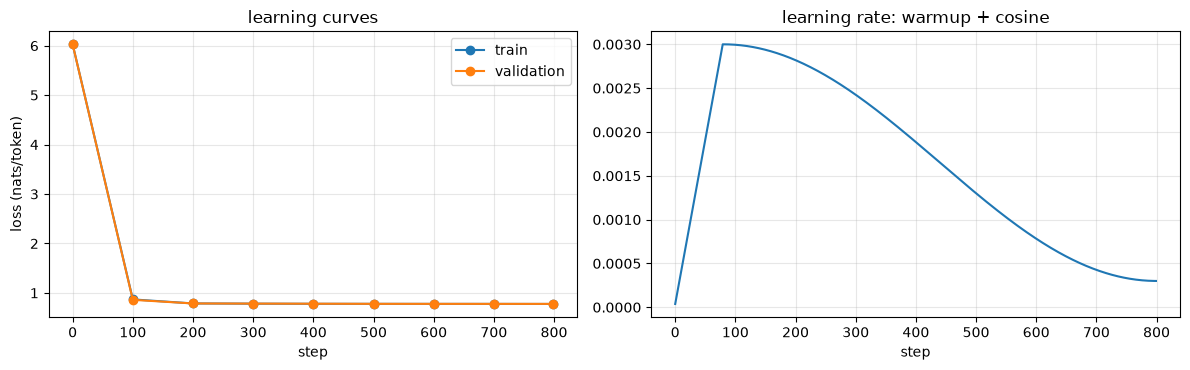

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(history["step"], history["train"], "o-", label="train")
ax[0].plot(history["step"], history["val"], "o-", label="validation")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss (nats/token)"); ax[0].set_title("learning curves"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(range(CFG["steps"]), [lr_at(s) for s in range(CFG["steps"])])
ax[1].set_xlabel("step"); ax[1].set_title("learning rate: warmup + cosine"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Evaluation: how good is it, really?

**Perplexity** = `exp(loss)`: the model is as uncertain as if it were choosing uniformly among that many tokens.

For the synthetic corpus we can do better than "lower is better": each sentence makes 4 independent choices among 8 options, i.e. carries exactly $4 \ln 8 = 8.32$ nats of information. Spread over the tokens of a sentence, that is the **irreducible loss** — no model, however large, can go below it. The gap between our validation loss and this floor is what is left to learn. (With real text the floor is unknown and much higher, which is why real LMs keep improving with scale.)

In [8]:
val_loss = estimate_loss("val")
print(f"validation loss {val_loss:.3f} | perplexity {math.exp(val_loss):.2f}")
if not (CFG["text_path"] and os.path.exists(CFG["text_path"])):
    floor = 4 * math.log(8) * N_SENTENCES / len(ids)                   # nats per token
    print(f"irreducible loss of the corpus {floor:.3f} (perplexity {math.exp(floor):.2f}) -> "
          f"our model is {100 * (val_loss / floor - 1):.1f}% above the floor")

validation loss 0.778 | perplexity 2.18
irreducible loss of the corpus 0.774 (perplexity 2.17) -> our model is 0.6% above the floor


## 6. Generation

Generation is a loop: run the model on the context, take the logits of the **last** position, turn them into a distribution, sample a token, append it, repeat.

- `temperature` < 1 sharpens the distribution (safer), > 1 flattens it (more creative / more mistakes)
- `top_k` keeps only the k most likely tokens; `top_p` keeps the smallest set whose probability reaches p

(For speed, real implementations keep a **KV-cache** so each step only processes the new token — see notebook 06.)

In [9]:
@torch.no_grad()
def generate(prompt, max_new_tokens=60, temperature=0.8, top_k=None, top_p=None):
    model.eval()
    idx = torch.tensor([tok.encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        logits, _ = model(idx[:, -CFG["block_size"]:])                     # the model only sees the last block_size tokens
        logits = logits[:, -1, :] / max(temperature, 1e-6)
        if top_k is not None:
            kth = logits.topk(top_k).values[:, -1:]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        probs = logits.softmax(-1)
        if top_p is not None:                                              # nucleus sampling: keep tokens until their cumulative probability reaches p
            sp, si = probs.sort(descending=True)
            keep = (sp.cumsum(-1) - sp) < top_p
            probs = torch.zeros_like(probs).scatter(-1, si, sp * keep)
            probs = probs / probs.sum(-1, keepdim=True)
        nxt = torch.multinomial(probs, 1) if temperature > 0 else logits.argmax(-1, keepdim=True)
        idx = torch.cat([idx, nxt], dim=1)
    return tok.decode(idx[0].tolist())

torch.manual_seed(1)
for name, kw in {"greedy": dict(temperature=0), "T=0.8, top-k 40": dict(temperature=0.8, top_k=40),
                 "T=1.0, top-p 0.9": dict(temperature=1.0, top_p=0.9)}.items():
    print(f"[{name}]\n  {generate('The old sailor', **kw)}\n")

[greedy]
  The old sailor painted the broken clock in the garden. The tired queen admired the broken clock in the garden. The little robot painted the wooden boat in the garden. The tired queen painted the secret map in the garden. The little robot built the broken clock in the garden. The tired queen painted the broken clock in



[T=0.8, top-k 40]
  The old sailor built the blue lantern behind the castle. A clever student lost a golden key near the river. The tired queen painted the wooden boat under the bridge. Our teacher followed a red umbrella by the sea. A young fox remembered the wooden boat in the library. A clever student admired the wooden boat near the



[T=1.0, top-p 0.9]
  The old sailor followed a red umbrella under the bridge. A young fox painted an empty bottle by the sea. The quiet painter built a red umbrella near the river. The quiet painter built a red umbrella in the library. My neighbour admired the blue lantern by the sea. The little robot built a strange letter on the



Check the samples: sentences should be **grammatical** in the corpus's grammar (subject → verb → object → place → period → new capitalized sentence). That structure was never programmed into the model — it was learned from next-token prediction alone.

In [10]:
# How often does the model produce a sentence that is valid under the corpus grammar?
valid = re.compile(r"^(?:%s) (?:%s) (?:%s) (?:%s)\.$" % tuple("|".join(map(re.escape, xs)) for xs in (SUBJECTS, VERBS, OBJECTS, PLACES)), re.I)
torch.manual_seed(0)
samples = " ".join(generate("The", max_new_tokens=60, temperature=0.8) for _ in range(10))
sents = [s.strip() + "." for s in samples.split(".")[1:-1] if s.strip()]          # drop the first sentence (it depends on the prompt) and the last (it gets cut off)
ok = sum(bool(valid.match(s)) for s in sents)
print(f"grammatical sentences: {ok}/{len(sents)} = {100 * ok / max(1, len(sents)):.0f}%")

grammatical sentences: 40/49 = 82%


## 7. Save and load

A checkpoint must contain everything needed to rebuild the model: the **config**, the **weights** and the **tokenizer** (a model is useless without the exact tokenizer it was trained with).

In [11]:
import tempfile
ckpt_path = os.path.join(tempfile.gettempdir(), "mini_gpt.pt")
torch.save({"config": {**CFG, "vocab_size": V}, "state_dict": model.state_dict(),
            "tokenizer": {"merges": [[a, b, i] for (a, b), i in tok.merges.items()]}}, ckpt_path)

ckpt = torch.load(ckpt_path, map_location=device)
c = ckpt["config"]
model2 = MiniGPT(c["vocab_size"], c["block_size"], c["d_model"], c["n_layers"], c["n_heads"]).to(device)
model2.load_state_dict(ckpt["state_dict"])
tok2 = BPETokenizer()
for a, b, i in ckpt["tokenizer"]["merges"]:
    tok2.merges[(a, b)] = i; tok2.vocab[i] = tok2.vocab[a] + tok2.vocab[b]
xb, _ = get_batch("val")
model.eval(); model2.eval()
with torch.no_grad():
    same = torch.allclose(model(xb)[0], model2(xb)[0])
print(f"saved to {ckpt_path} ({os.path.getsize(ckpt_path) / 1e6:.1f} MB) | reloaded model identical: {same} | "
      f"tokenizer identical: {tok2.encode(text[:500]) == tok.encode(text[:500])}")

saved to C:\Users\Andy\AppData\Local\Temp\mini_gpt.pt (7.4 MB) | reloaded model identical: True | tokenizer identical: True

## Where to go next

| You want to understand… | Notebook |
|---|---|
| how BPE vocabulary size trades off sequence length | 01 · tokenization |
| why RoPE works, GQA/MLA and the KV-cache | 02 · attention |
| long-context attention variants | 03 · efficient attention |
| Mixture-of-Experts | 04 · FFN & MoE |
| LR schedules, scaling, the training dashboard | 05 · pre-training |
| fast generation: KV-cache, speculative decoding, batching | 06 · inference |
| turning this into an assistant: SFT, LoRA, DPO, GRPO | 07, 08 |
| making it smaller: INT8 / INT4 / NF4 | 09 · quantization |

**Exercises:** (1) set `text_path` to tiny Shakespeare and train for 3000 steps; (2) replace `SwiGLU` with a plain GELU MLP of the same size and compare the final loss; (3) remove RoPE and watch what happens to the grammar; (4) add a KV-cache to `generate` and measure the speed-up.